In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

def get_range(df, arange, erange, Irange, osc_or_prop=True, no_res=True):
    amid = np.mean(arange); adist = abs(arange[0] - arange[1])/2
    emid = np.mean(erange); edist = abs(erange[0] - erange[1])/2
    Imid = np.mean(Irange); Idist = abs(Irange[0] - Irange[1])/2
    
    if osc_or_prop:
        inda = np.where(abs(df['OscSMA'] - amid) <= adist)[0]
        inde = np.where(abs(df['OscEcc'] - emid) <= edist)[0]
        indI = np.where(abs(df['OscInc']*180/np.pi - Imid) <= Idist)[0]
    else:
        inda = np.where(abs(df['PropSMA'] - amid) <= adist)[0]
        inde = np.where(abs(df['PropEcc'] - emid) <= edist)[0]
        indI = np.where(abs(np.arcsin(df['PropSinI'])*180/np.pi - Imid) <= Idist)[0]

    if no_res:
        ind_res = np.where(abs(df['PropSMA'] - 43.67) <= 0.05)[0]; ind_res2 = np.where(abs(df['PropSMA'] - 42.275) <= 0.05)[0]
        ind_res3 = np.where(abs(df['PropSMA'] - 44.5) <= 0.05)[0]; ind_res4 = np.where(abs(df['PropSMA'] - 47.78) <= 0.05)[0]
        ind_res5 = np.where(abs(df['PropSMA'] - 41.05) <= 0.05)[0]
        ind_res = np.union1d(ind_res, ind_res2); ind_res = np.union1d(ind_res, ind_res3)
        ind_res = np.union1d(ind_res, ind_res4); ind_res = np.union1d(ind_res, ind_res5)

        indget = np.intersect1d(inda, inde); indget = np.intersect1d(indget, indI)
    
        indget = np.setdiff1d(indget, ind_res)
        
    return df.iloc[indget]


grid_df = pd.read_csv('../data/ctno_grid_pe_csv.zip', index_col=0)
tno_df = pd.read_csv('../data/AllTNOs_500myr_pe.csv', index_col=0)



### We start by reading in our two datasets,
 - grid_df: The ~500,000 synthetic TNOs and their associated oscualting elements and proper elements.
 - tno_df: The catalog of known TNO proper elements.

Let's start by visualizing each of these datasets in osculating element space. We show the density of the uniform grid in a,e and a,I space, while plotting the observed catalog of known TNOs in red. 

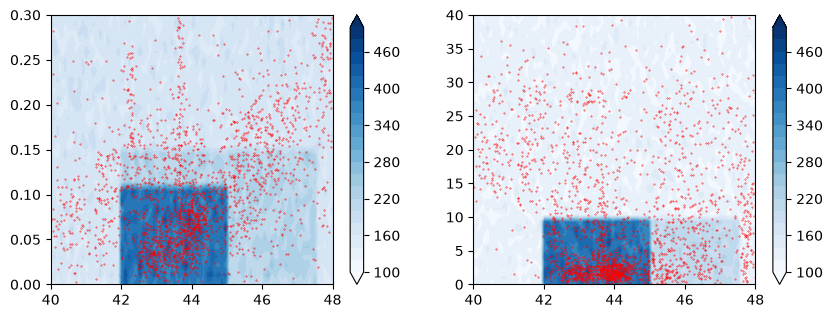

In [2]:
bina = np.linspace(40, 48, 81); bine = np.linspace(0,0.3,31); binI = np.linspace(0,40,41)
bina2 = np.linspace(40, 48, 80); bine2 = np.linspace(0,0.3,30); binI2 = np.linspace(0,40,40)

fig, ax = plt.subplots(1,2, figsize=(10, 3.5), sharex=True)

histe, edge1, edge2 = np.histogram2d(grid_df['OscSMA'], grid_df['OscEcc'], bins=(bina, bine))
histI, edge3, edge4 = np.histogram2d(grid_df['OscSMA'], grid_df['OscInc']*180/np.pi, bins=(bina, binI))
c0 = ax[0].contourf(bina2, bine2, histe.T, levels=np.linspace(100,500,21), extend='both', cmap='Blues')
c1 = ax[1].contourf(bina2, binI2, histI.T, levels=np.linspace(100,500,21), extend='both', cmap='Blues')

ax[0].scatter(tno_df['OscSMA'], tno_df['OscEcc'], s=0.1, c='r')
ax[1].scatter(tno_df['OscSMA'], tno_df['OscInc']*180/np.pi, s=0.1, c='r')

fig.colorbar(c0,ax=ax[0]); fig.colorbar(c1,ax=ax[1])

#c0 = ax[0].contour(bina2, bine2, histe.T, levels=[200,300],colors=['k','k'])
#c1 = ax[1].contour(bina2, binI2, histI.T, levels=[180,300],colors=['k','k'])

ax[0].set_xlim(40,48); ax[0].set_ylim(0,0.3); ax[1].set_ylim(0,40)
plt.show()

### We can clearly see in the grid that there are three separate uniform sets of objects in the synthetic grid,
1) Full Classical belt:
   - 400,000 particles with initial a:[40,48], e:[0,0.3], and I:[0,40]
   - Resolution with da=0.1, de=0.01, dI=1 ~ 4 particles per bin
   - Indices: [0 : 398,100]
2) Cold Classical belt: 
   - ~50,000 particles with initial a:[42,47.5], e:[0,0.15], and I:[0,10]
   - Resolution with da=0.1, de=0.01, dI=1 ~ 10 particles per bin
   - Indices: [398,100 : 447,900]
3) Cold Classical Inner-main + Kernel belt:
   - ~50,000 particles with initial a:[42,45], e:[0,0.1], and I:[0,10]
   - Resolution with da=0.1, de=0.01, dI=1 ~ 26 particles per bin
   - Indices: [447,900 : 497,950]

##### The 2nd set of ~50,000 particles effectively doubles the resolution of particles in the region with respect to the full dataset. 
##### The 3rd set of ~50,000 particles increases the resolution by 6.5x with respect to the full dataset. 

## However, users must be careful when computing a transfer function to make sure that the grid of particles they are using to find nearest neighbors in is uniform, at least among the space that the subset of the known TNOs lies within. 

We restrict our example in this notebook to the inner-main belt + kernel region which is totally uniform, but users who wish to see the transfer function at higher au or eccentricity will need to slice te grid_df appropriately to avoid a non-uniform grid.

## Generating the Sample for Analysis
The catalog of TNO proper elements contains all TNOs, or objects with semi-major axes > 30 au. However, we generally are only interested in a subset of TNOs, namely the Classical belt, or more specifically in this case, the inner-main belt and the kernel. In addition, to avoid the impact of bias, we wish to restrict our catalog of known objects to those with I < 10 degrees. 

Also note that we wish to avoid including resonant objects, or objects even NEAR major resonances, from our analysis. Thus the *get_range* function above includes a feature to remove objects with proper semi-major axes within 0.05 au of the major resonances from both our synthetic sample, and the sample of TNOs we wish to analyze.

### The *get_range* function will automatically cut down the dataframe to a specific range in oscualting or proper elements. It will also remove objects within 0.05 au of the major resonances. 

C:\Users\dalli\anaconda3\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: invalid value encountered in arcsin
  result = getattr(ufunc, method)(*inputs, **kwargs)


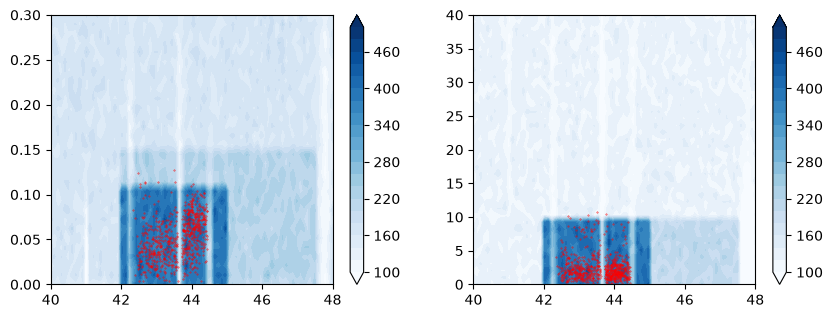

In [3]:
sub_grid_df = get_range(grid_df, (40, 48), (0,1), (0,40), osc_or_prop=True)
sub_tno_df = get_range(tno_df, (42.3, 44.5), (0,0.1), (0,10), osc_or_prop=False)

bina = np.linspace(40, 48, 81); bine = np.linspace(0,0.3,31); binI = np.linspace(0,40,41)
bina2 = np.linspace(40, 48, 80); bine2 = np.linspace(0,0.3,30); binI2 = np.linspace(0,40,40)

fig, ax = plt.subplots(1,2, figsize=(10, 3.5), sharex=True)

histe, edge1, edge2 = np.histogram2d(sub_grid_df['OscSMA'], sub_grid_df['OscEcc'], bins=(bina, bine))
histI, edge3, edge4 = np.histogram2d(sub_grid_df['OscSMA'], sub_grid_df['OscInc']*180/np.pi, bins=(bina, binI))
c0 = ax[0].contourf(bina2, bine2, histe.T, levels=np.linspace(100,500,21), extend='both', cmap='Blues')
c1 = ax[1].contourf(bina2, binI2, histI.T, levels=np.linspace(100,500,21), extend='both', cmap='Blues')

ax[0].scatter(sub_tno_df['OscSMA'], sub_tno_df['OscEcc'], s=0.1, c='r')
ax[1].scatter(sub_tno_df['OscSMA'], sub_tno_df['OscInc']*180/np.pi, s=0.1, c='r')

fig.colorbar(c0,ax=ax[0]); fig.colorbar(c1,ax=ax[1])

#c0 = ax[0].contour(bina2, bine2, histe.T, levels=[200,300],colors=['k','k'])
#c1 = ax[1].contour(bina2, binI2, histI.T, levels=[180,300],colors=['k','k'])

ax[0].set_xlim(40,48); ax[0].set_ylim(0,0.3); ax[1].set_ylim(0,40)
plt.show()

## Note that while the grid of synthetic particles is not uniform, it is uniform among the region we are analyzing, the Cold Classicla inner-main + kernel belts. Because of this, the non-uniformity of the grid will not impact the nearest neighbors that are sampled. 

#### This may not be true if we were to sample known TNOs in the outer main belt as well, or at higher eccentricities. 

In [4]:

# Initialize the KDTree using an n-dimensional stack of the TNO proper elements. 
# We include constants ka = 5/4, ke = 2, and ksinI = 2 in line with the Zappala 1990 clustering method. 
# We also normalize the proper semi-major axes by 43.4 au, which lies at the center of the range we are considering in the Classical belt. 
proper_elements = np.column_stack([np.sqrt(5/4)*sub_grid_df['PropSMA']/43.4, 
                                   np.sqrt(2)*sub_grid_df['PropEcc'], 
                                   np.sqrt(2)*sub_grid_df['PropSinI']])

from scipy.spatial import KDTree
tree = KDTree(proper_elements)

def hcm(a, rmsa, rmse, rmsi):   
    G = 6.673e-11
    M = 1.989e30
    n = np.sqrt(G*M/(a*1.496e11)**3)
    return n*abs(a)*1.498e11*np.sqrt(5/4*(rmsa/a)**2+2*rmse**2+2*rmsi**2)


def get_transfer_weights(a_obs, e_obs, sini_obs, hcm_obs, k=200, a0=None, e0=None, i0=None, tree = None):
    """
    Returns initial conditions of k nearest neighbors in PROPER
    element space, with weights based ONLY on proper element distance.
    Initial conditions are carried along passively.
    Input i0 is in units of radians
    Input ip_obs is in sinI units. 

    ap, ep, ip are proper elements of your sample
    i0, a0, e0 is osculating (t=0) elements of your 
    """
    query = np.array([[np.sqrt(5/4)*a_obs/43.4, np.sqrt(2)*e_obs, np.sqrt(2)*sini_obs]])
    dists, idx = tree.query(query, k=k)

    h = np.median(dists)   # adaptive bandwidth
    stab = np
    weights = np.exp(-0.5 * (dists[0] / h)**2) 
    weights /= weights.sum()

    epsilon = np.percentile(hcm_obs, 5)  # floor at 5th percentile
    stab_weights = 1.0 / (hcm_obs[idx[0]] + epsilon)

    # Normalize stability weights independently before combining
    stab_weights /= stab_weights.sum()

    # Combined weight
    combined = weights * stab_weights
    combined /= combined.sum()

    # Initial conditions are just passengers — not used for weighting
    return a0[idx[0]], e0[idx[0]], i0[idx[0]], weights, idx[0]


print("Pre-computing transfer weights for all observed objects...")

transfer_w  = []   # Weights for each nearest neighbor, computed from the distance metric from the known TNO, and the stability of the neighbors.
transfer_a0 = []; transfer_e0 = []; transfer_i0 = [] #The initial osculating elements for the nearest neighbors
transfer_inds = [] #The indices of the nearest neighbors in the synthetic TNO sub-grid.

# We compute the Distance Metric indicator for each individual synthetic TNO. This corresponds to the stability of the particles, 
# which contributes to the weight parameter for each of the nearest neighbors. 
cluster = np.array(hcm(sub_grid_df['PropSMA'], sub_grid_df['PropSMA_err'], sub_grid_df['PropEcc_err'], sub_grid_df['PropSinI_err']))

#
for ap_k, ep_k, ip_k in zip(sub_tno_df['PropSMA'], sub_tno_df['PropEcc'], sub_tno_df['PropSinI']):
    a0_nn, e0_nn, i0_nn, w_nn, inds = get_transfer_weights(ap_k, ep_k, ip_k, cluster, k=25, tree=tree, 
                                                           a0=sub_grid_df['OscSMA'].to_numpy(),
                                                           e0=sub_grid_df['OscEcc'].to_numpy(), 
                                                           i0=sub_grid_df['OscInc'].to_numpy())
    
    transfer_a0.append(a0_nn); transfer_e0.append(e0_nn); transfer_i0.append(i0_nn)
    transfer_w.append(w_nn); transfer_inds.append(inds)


#Convert lists to numpy arrays
transfer_a0 = np.array(transfer_a0); transfer_e0 = np.array(transfer_e0); transfer_i0 = np.array(transfer_i0)  
transfer_w  = np.array(transfer_w); transfer_inds  = np.array(transfer_inds)   

Pre-computing transfer weights for all observed objects...


C:\Users\dalli\anaconda3\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: invalid value encountered in sqrt
  result = getattr(ufunc, method)(*inputs, **kwargs)


### We search for the nearest neighbors with respect to their proper elements of our real TNO subset within the grid of synthetic particles. The resulting indices of the nearest neighbors lead to the initial osculating elements of the nearest neighbors representing a transfer function from initial elements to proper elements.


### We can visualize this transfer functions by showing the 2D histograms in osculating elements of the selected neighbors as compared to the actual catalog of proper elements. 

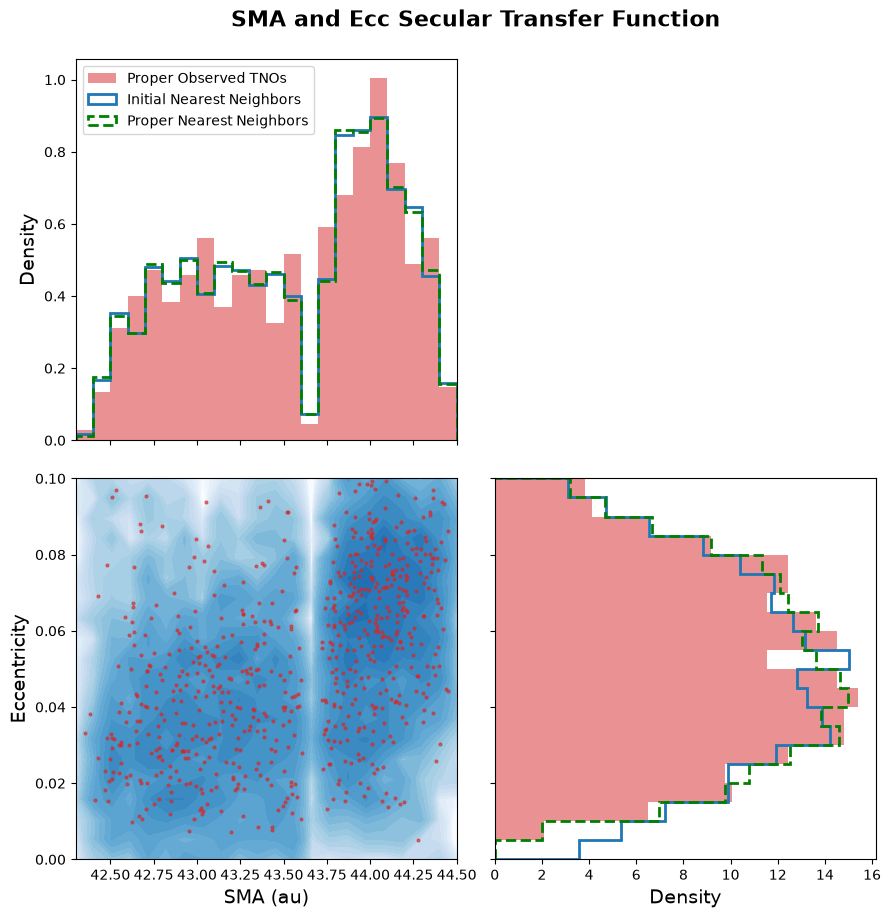

In [5]:
bina = np.linspace(42.3, 44.5, 23)
bine = np.linspace(0,0.1,21)
binI = np.linspace(0,10,21)

bina2 = np.linspace(42.3, 44.5, 22)
bine2 = np.linspace(0,0.1,20)
binI2 = np.linspace(0,10,20)

fig = plt.figure(figsize=(10, 10))
gs = fig.add_gridspec(
    2, 2, 
    width_ratios=(1, 1),  
    height_ratios=(1, 1),  
    left=0.1, right=0.9, bottom=0.1, top=0.9,
    wspace=0.1, hspace=0.1 
)

ax_main = fig.add_subplot(gs[1, 0])  # Bottom-left: Main 2D hist
ax_top = fig.add_subplot(gs[0, 0], sharex=ax_main)   # Top-left: X marginal hist
ax_right = fig.add_subplot(gs[1, 1], sharey=ax_main) # Bottom-right: Y marginal hist

histe, edge1, edge2 = np.histogram2d(transfer_a0.flatten(), transfer_e0.flatten(), bins=(bina, bine), weights=transfer_w.flatten(), density=True)

ax_main.contourf(bina2, bine2, histe.T + 1e-2, levels=np.geomspace(1e-1,1e2, 31), norm=LogNorm(), extend='both', cmap='Blues')
x1,x2 = ax_main.get_xlim()
y1,y2 = ax_main.get_ylim()

ax_main.scatter(sub_tno_df['PropSMA'], sub_tno_df['PropEcc'], s=4, alpha=0.6, c='tab:red', label='TNO Proper Elements')


ax_top.hist(sub_tno_df['PropSMA'], bins=edge1, alpha=0.5, color='tab:red', density=True, label='Proper Observed TNOs')
ax_right.hist(sub_tno_df['PropEcc'], bins=edge2, alpha=0.5, color='tab:red', density=True,orientation="horizontal")

ax_top.hist(transfer_a0.flatten(), bins=edge1, color="tab:blue", histtype='step', weights=transfer_w.flatten(), density=True, alpha=1, label='Initial Nearest Neighbors', lw=2, ls='-')
ax_right.hist(transfer_e0.flatten(), bins=edge2, orientation="horizontal", color="tab:blue", histtype='step', weights=transfer_w.flatten(), density=True, alpha=1, lw=2, ls='-')

#ax_top.hist(sub_tno_df['PropSMA'], bins=edge1, histtype='step', color='r', density=True, label='Observed TNOs')
#ax_right.hist(sub_tno_df['PropEcc'], bins=edge2, histtype='step', color='r', density=True,orientation="horizontal")

ax_top.hist(sub_grid_df['PropSMA'].iloc[transfer_inds.flatten()], bins=edge1, color="g", histtype='step', ls='--', lw=2,weights=transfer_w.flatten(), density=True, label='Proper Nearest Neighbors')
ax_right.hist(sub_grid_df['PropEcc'].iloc[transfer_inds.flatten()], bins=edge2, orientation="horizontal", color="g", lw=2, histtype='step', ls='--', weights=transfer_w.flatten(), density=True)

ax_main.set_xlim(x1,x2)
ax_main.set_ylim(y1,y2)
plt.setp(ax_top.get_xticklabels(), visible=False)
plt.setp(ax_right.get_yticklabels(), visible=False)

fig.suptitle("SMA and Ecc Secular Transfer Function", y=0.95, fontsize=16, weight="bold")

ax_top.legend()
ax_main.set_xlabel('SMA (au)', fontsize=14)
ax_main.set_ylabel('Eccentricity', fontsize=14)

ax_top.set_ylabel('Density', fontsize=14)
ax_right.set_xlabel('Density', fontsize=14)
plt.show()



The blue background represents th

#### We note that the transfer function in eccentricity struggles to reproduce the underdensity of particles at Proper ecc ~ 0.05 - 0.06. This feature is found within the inner-main belt region, and results not from secular forcing and instability, but from dynamical instability caused by the sweeping 7:4 mean motion resonance during Neptune's late stage migration (Morbidelli et al. 2014). As such, this discontinuity is not well-captured in the transfer function.

#### However, note that the transfer function does effectively capture the effect of Neptune forcing, which causes proper eccentricities to always exceed e > 0, even if the initial eccentricities were very close to 0.

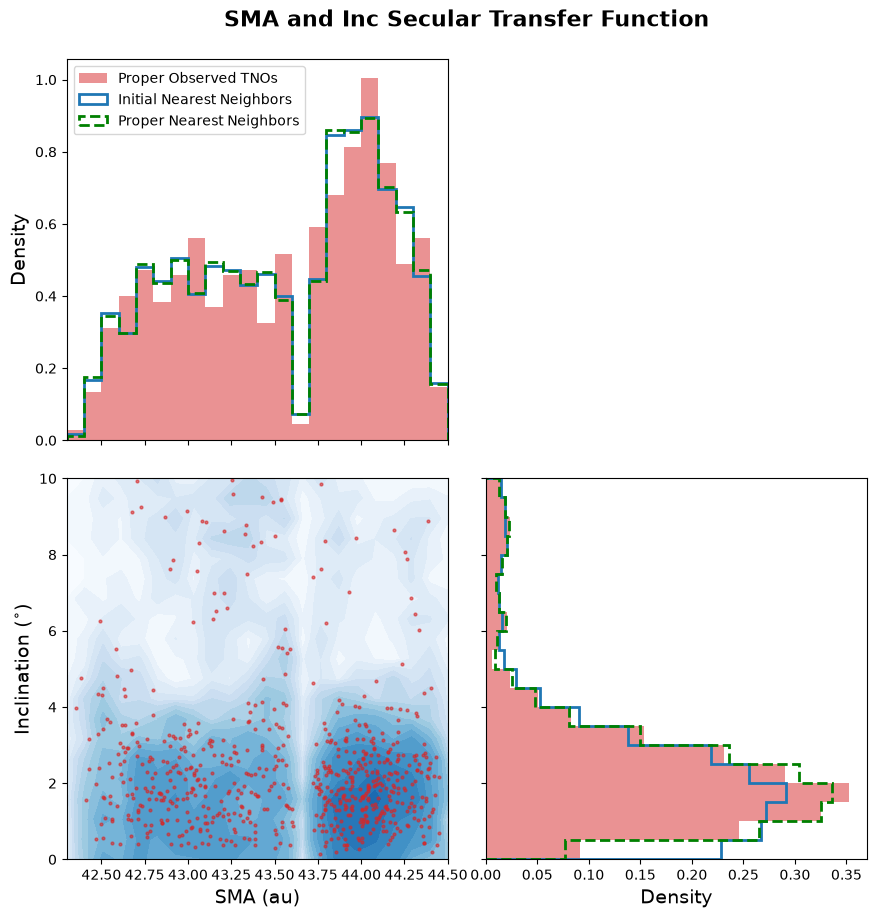

In [6]:
import numpy as np
import matplotlib.pyplot as plt

bina = np.linspace(42.3, 44.5, 23)
bine = np.linspace(0,0.1,21)
binI = np.linspace(0,10,21)

bina2 = np.linspace(42.3, 44.5, 22)
bine2 = np.linspace(0,0.1,20)
binI2 = np.linspace(0,10,20)

# 2. Define layout dimensions using GridSpec
fig = plt.figure(figsize=(10, 10))
gs = fig.add_gridspec(
    2, 2, 
    width_ratios=(1, 1),    # Main plot is 4x wider than the right histogram
    height_ratios=(1, 1),   # Main plot is 4x taller than the top histogram
    left=0.1, right=0.9, bottom=0.1, top=0.9,
    wspace=0.1, hspace=0.1 # Tiny spacing to keep them close together
)

# 3. Create the individual subplots
ax_main = fig.add_subplot(gs[1, 0])  # Bottom-left: Main 2D hist
ax_top = fig.add_subplot(gs[0, 0], sharex=ax_main)   # Top-left: X marginal hist
ax_right = fig.add_subplot(gs[1, 1], sharey=ax_main) # Bottom-right: Y marginal hist

# 4. Plot the 2D Histogram
# Save bin limits so the 1D histograms share the exact same bins
#counts, xedges, yedges, im = ax_main.hist2d(x, y, bins=40, cmap="viridis")
histI, edge1, edge2 = np.histogram2d(transfer_a0.flatten(), transfer_i0.flatten()*180/np.pi, bins=(bina, binI), weights=transfer_w.flatten(), density=True)

ax_main.contourf(bina2, binI2, histI.T + 1e-2, levels=np.geomspace(1e-2,1e0, 21), norm=LogNorm(), extend='both', cmap='Blues')
x1,x2 = ax_main.get_xlim()
y1,y2 = ax_main.get_ylim()

ax_main.scatter(sub_tno_df['PropSMA'], 180/np.pi*np.arcsin(sub_tno_df['PropSinI']), s=4, alpha=0.6, c='tab:red', label='TNO Proper Elements')

ax_top.hist(sub_tno_df['PropSMA'], bins=edge1, alpha=0.5, color='tab:red', density=True, label='Proper Observed TNOs')
ax_right.hist(180/np.pi*np.arcsin(sub_tno_df['PropSinI']), bins=edge2, alpha=0.5, color='tab:red', density=True,orientation="horizontal")

ax_top.hist(transfer_a0.flatten(), bins=edge1, color="tab:blue", histtype='step', weights=transfer_w.flatten(), density=True, alpha=1, label='Initial Nearest Neighbors', lw=2, ls='-')
ax_right.hist(transfer_i0.flatten()*180/np.pi, bins=edge2, orientation="horizontal", color="tab:blue", histtype='step', weights=transfer_w.flatten(), density=True, alpha=1, lw=2, ls='-')


ax_top.hist(sub_grid_df['PropSMA'].iloc[transfer_inds.flatten()], bins=edge1, color="g", histtype='step', ls='--', lw=2,weights=transfer_w.flatten(), density=True, label='Proper Nearest Neighbors')
# For the right histogram, use orientation='horizontal' so it matches the Y-axis
ax_right.hist(180/np.pi*np.arcsin(sub_grid_df['PropSinI'].iloc[transfer_inds.flatten()]), bins=edge2, orientation="horizontal", color="g", lw=2, histtype='step', ls='--', weights=transfer_w.flatten(), density=True)


ax_main.set_xlim(x1,x2)
ax_main.set_ylim(y1,y2)
# 6. Clean up axes and visibility
# Hide overlapping labels on the sidecars since they share axes with the main plot
plt.setp(ax_top.get_xticklabels(), visible=False)
plt.setp(ax_right.get_yticklabels(), visible=False)

# Optional: Add a title over everything
fig.suptitle("SMA and Inc Secular Transfer Function", y=0.95, fontsize=16, weight="bold")

ax_top.legend()

ax_main.set_xlabel('SMA (au)', fontsize=14)
ax_main.set_ylabel(r'Inclination $(^{\circ})$', fontsize=14)

ax_top.set_ylabel('Density', fontsize=14)
ax_right.set_xlabel('Density', fontsize=14)
plt.show()



#### In contrast, the transfer function in inclination space does effectively reproduce the observed TNO inclination distribution, which is shaped primarily by secular effects, with small residuals at almost every bin. 

#### The transfer function also shows that the distribution of particles with initial inclinations from 4 < I < 6 degree could have been twice as dense as the number of measured proper inclinations, with many of these particles evolving to higher proper inclinations. 

#### We also see that a large number of particles could have had small initial inclinations, but interactions with the Laplace plane cause the proper inclinations to be higher.